### Libreta para EDA ya usando los datos almacenados en Parquet

In [1]:
import pandas as pd
import numpy as np
from datetime import date
from pathlib import Path
import matplotlib.pyplot as plt
from pathlib import Path
import re

In [2]:
def leer_archivos_de_un_anio(direccion, anio):
    folder_path = Path(direccion)

    df = pd.concat(
        [
            pd.read_parquet(file).assign(file_name=file.name)
            for file in folder_path.glob(f"*_{anio}_*.parquet")
        ],
        ignore_index=True
    )

    return df

In [3]:
def leer_todos_los_archivos(direccion):
    folder_path = Path(direccion)

    df = pd.concat(
        [
            pd.read_parquet(file).assign(file_name=file.name)
            for file in folder_path.glob("*.parquet")
        ],
        ignore_index=True
    )

    return df

In [4]:
def leer_rango(direccion, desde=(2014, 12), hasta=(9999, 12), columnas=None):
    patron = re.compile(r"datos_abiertos_(\d{4})_(\d{2})\.parquet$")
    archivos = []
    for ruta in sorted(Path(direccion).glob("datos_abiertos_*.parquet")):
        m = patron.search(ruta.name)
        if m and desde <= (int(m[1]), int(m[2])) <= hasta:
            archivos.append(ruta)
    if not archivos:
        raise FileNotFoundError(f"No hay Parquet entre {desde} y {hasta} en '{direccion}'")
    
    df = pd.concat(
        [
            pd.read_parquet(r, columns=columnas).assign(nombre_archivo=r.name) for r in archivos
        ],
        ignore_index=True)

    return df

In [5]:
def redondear_a_primer_dia_del_mes(dt_col):
    col_redondeado = dt_col.astype(str).str.slice(stop=8) + "01"
    return pd.to_datetime(col_redondeado)

In [6]:
DATA_DIR = "../data/external"
df = leer_todos_los_archivos(DATA_DIR)

In [7]:
df = leer_rango(DATA_DIR, (2020, 1), (2026, 9))

In [ ]:
groupedby = df.groupby(redondear_a_primer_dia_del_mes(df["inicio_del_viaje"]))['viaje_id'].count()

plt.plot(groupedby.index, groupedby)
plt.xlabel("Fecha de inicio de viaje")
plt.ylabel("Número de viajes")
plt.show()

ValueError: Invalid frequency: M. Failed to parse with error message: ValueError("'M' is no longer supported for offsets. Please use 'ME' instead.")

In [9]:
# Solo Genero y Año de nacimiento tienen nulls
# Pendiente revisar si hay strings actuando como nulos
df.isna().sum()

viaje_id                   0
usuario_id                 0
genero                135232
anio_de_nacimiento     33796
inicio_del_viaje           0
fin_del_viaje              0
origen_id                  0
destino_id                 0
nombre_archivo             0
dtype: int64

In [10]:
# No hay correlacion entre los nulos de Genero y los nulos de año de nacimiento
null_matrix = df[["genero","anio_de_nacimiento"]].isnull().astype(int)
null_corr = null_matrix.corr(method='pearson')
null_corr

,genero,anio_de_nacimiento
genero,1.000000,0.058628
anio_de_nacimiento,0.058628,1.000000


In [11]:
# 29779602 records no tienen ninguna de estas columnas (Genero, Año de nacimiento) nulas
# 165406 tienen una u otra nula
# 7477 tienen ambas nulas
null_matrix.sum(axis=1).value_counts()

0    26224258
1      160780
2        4124
Name: count, dtype: int64

In [12]:
cat_cols = df.select_dtypes(include=["str","object"]).columns.tolist()
num_cols = df.select_dtypes(include=["number"]).columns.tolist()
time_cols = df.select_dtypes(include=["datetime"]).columns.tolist()
assert len(cat_cols) + len(num_cols) + len(time_cols) == len(df.columns)

In [13]:
cat_stats_df = df[cat_cols].describe().T
cat_stats_df

# El archivo 2020_02 (justo antes del inicio de la pandemia) es el que tiene más records (del 2020 en adelante)
# No todos los viajes son únicos, algunos Ids se duplican
# 72% de los registros son de hombres

,count,unique,top,freq
genero,26253930,2,M,19130897
nombre_archivo,26389162,79,datos_abiertos_2026_09.parquet,490056


In [14]:
df["genero"].value_counts()*100/len(df)

genero
M    72.495280
F    26.992267
Name: count, dtype: float64

In [15]:
# Qué ocurre cuando Genero es nulo?
df[df["genero"].isnull()].head(100)

,viaje_id,usuario_id,genero,anio_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,nombre_archivo
230,14420499,634722,NaN,<NA>,2020-01-01 10:00:48,2020-01-01 10:16:46,77,36,datos_abiertos_2020_01.parquet
334,14420610,634711,NaN,<NA>,2020-01-01 10:49:31,2020-01-01 11:05:36,28,56,datos_abiertos_2020_01.parquet
335,14420611,634711,NaN,<NA>,2020-01-01 10:49:37,2020-01-01 11:05:24,28,56,datos_abiertos_2020_01.parquet
368,14420644,634725,NaN,<NA>,2020-01-01 10:59:51,2020-01-01 11:14:58,198,50,datos_abiertos_2020_01.parquet
378,14420654,634722,NaN,<NA>,2020-01-01 11:04:27,2020-01-01 11:25:08,36,34,datos_abiertos_2020_01.parquet
...,...,...,...,...,...,...,...,...,...
26890,14453499,635541,NaN,<NA>,2020-01-05 10:30:26,2020-01-05 10:43:53,133,221,datos_abiertos_2020_01.parquet
26891,14453500,635541,NaN,<NA>,2020-01-05 10:30:30,2020-01-05 10:44:45,133,221,datos_abiertos_2020_01.parquet
26901,14453510,635544,NaN,<NA>,2020-01-05 10:31:38,2020-01-05 10:45:57,196,50,datos_abiertos_2020_01.parquet
26916,14453525,635552,NaN,<NA>,2020-01-05 10:33:33,2020-01-05 12:19:07,194,194,datos_abiertos_2020_01.parquet


In [16]:
num_stats_df = df[num_cols].describe().T
num_stats_df["kurt"] = df[num_cols].kurt()
num_stats_df["skew"] = df[num_cols].skew()
num_stats_df

# Año de nacimiento mínimo de 1 está muy raro
# Año de nacimiento máximo de 2023 también

,count,mean,std,min,25%,50%,75%,max,kurt,skew
viaje_id,26389162.0,30579177.56663,9263521.636921,14420217.0,22414442.25,31019453.5,38647551.75,46255558.0,-1.234374,-0.039108
usuario_id,26389162.0,1495712.51178,1440552.72449,102.0,424402.0,767145.0,2265472.0,5006315.0,-0.141086,1.073614
anio_de_nacimiento,26355366.0,1989.057583,17.043063,1.0,1984.0,1992.0,1997.0,2023.0,7575.476138,-67.445369
origen_id,26389162.0,145.32726,105.669565,2.0,51.0,142.0,235.0,519.0,-0.919469,0.448175
destino_id,26389162.0,145.960128,107.949462,2.0,51.0,134.0,248.0,519.0,-0.97474,0.460614


In [17]:
# Se quitan los datos donde el año de nacimiento es menor a 1900
df = df[df["anio_de_nacimiento"] >= 1900]

In [18]:
# Solo hay 3 años de nacimiento distintos mayores a 2010
df[df["anio_de_nacimiento"] > 2010].anio_de_nacimiento.value_counts()

anio_de_nacimiento
2023    1151
2021     568
2022     374
Name: count, dtype: Int64

In [19]:
# Para evaluar estos registros se toma un approach diferente
# se estima la edad aproximada de la persona cuando ocurrió el viaje
df["edad_aproximada"] = df["inicio_del_viaje"].dt.year - df["anio_de_nacimiento"]

In [20]:
# Todos los que pudieran tener una edad de 5 años o menos, tienen entre 0 y 2 años
df[df["edad_aproximada"] < 6].edad_aproximada.value_counts()

edad_aproximada
1    1095
0     569
2     429
Name: count, dtype: Int64

In [21]:
# Por lo tanto, se interpretan como records erroneos y se eliminan
df = df[df["edad_aproximada"] > 5]

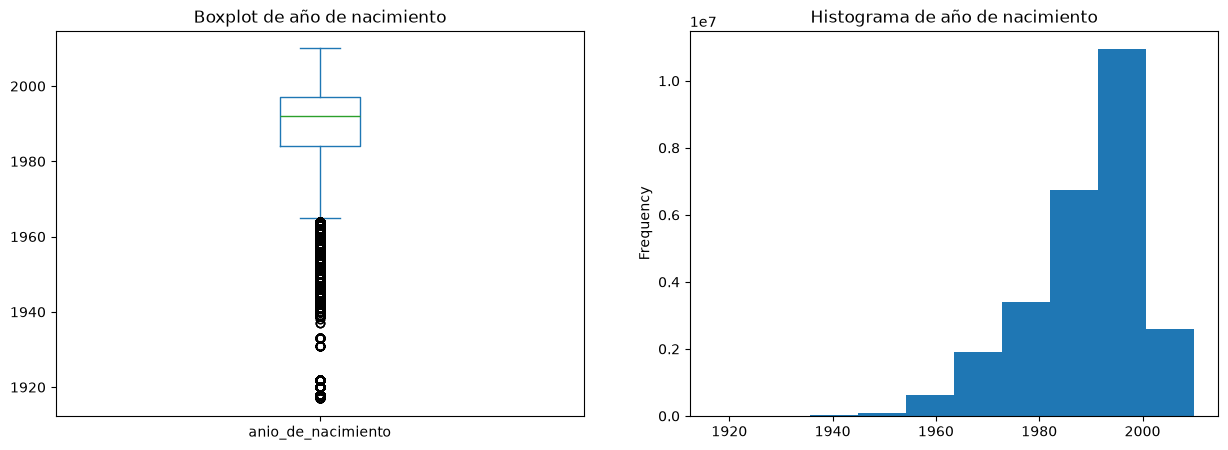

In [22]:
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
df.anio_de_nacimiento.plot.box()
plt.title("Boxplot de año de nacimiento")

plt.subplot(1,2,2)
df.anio_de_nacimiento.plot.hist()
plt.title("Histograma de año de nacimiento")

plt.show()

In [23]:
nom_df = pd.read_csv("../data/external/nomenclatura_estaciones.csv")

In [24]:
nom_df.head(10)

,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11
5,8,(GDL-006) C. Venustiano Carranza /C. Reforma,20.680717,-103.344415,11
6,9,(GDL-007) C. Epigmenio Glez./Av. Cristobal C.,20.666771,-103.350562,15
7,10,(GDL-008) C. Ignacio Zaragoza / C. J. Angulo,20.681953,-103.349992,15
8,11,(GDL-009) Calz. Federalismo/ C. J. Angulo,20.682077,-103.353835,23
9,12,(GDL-010) C. Cruz verde / C. Joaquin Angulo,20.681852,-103.357338,15


In [25]:
# Si un id no está en el archivo de la nomenclatura, no es posible analizarlo para el problema P2. Los records con estos ids se eliminan
def descartar_records_con_id_inexistente_en_nomenclatura(datos_df, nomenclatura_df, col_origen, col_destino, col_id_nomenclatura):
    origen_id_no_en_nomenclatura = ~(datos_df[col_origen].isin(nomenclatura_df[col_id_nomenclatura].unique()))
    destino_id_no_en_nomenclatura = ~(datos_df[col_destino].isin(nomenclatura_df[col_id_nomenclatura].unique()))
    return datos_df[~(origen_id_no_en_nomenclatura | destino_id_no_en_nomenclatura)]

In [26]:
df = descartar_records_con_id_inexistente_en_nomenclatura(df, nom_df, "origen_id", "destino_id", "id")

In [27]:
df["duracion_del_viaje"] = (df.fin_del_viaje - df.inicio_del_viaje).dt.total_seconds()

In [28]:
df.shape

(26348057, 11)

In [29]:
df["duracion_del_viaje"].sort_values(ascending=False)

3292526     1689046.0
108473      1487001.0
4042178     1456986.0
3897347     1039488.0
2380157      840784.0
              ...    
13241055          0.0
14921526          0.0
17207430          0.0
8602122           0.0
14619750          0.0
Name: duracion_del_viaje, Length: 26348057, dtype: float64

In [30]:
df[df["duracion_del_viaje"] > 60*60*24].sort_values(by="duracion_del_viaje", ascending=False)

,viaje_id,usuario_id,genero,anio_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,nombre_archivo,edad_aproximada,duracion_del_viaje
3292526,18537759,626320,M,1997,2021-03-03 20:57:57,2021-03-23 10:08:43,180,75,datos_abiertos_2021_03.parquet,24,1689046.0
108473,14551302,363347,F,1986,2020-01-13 07:06:24,2020-01-30 12:09:45,230,227,datos_abiertos_2020_01.parquet,34,1487001.0
4042178,19426506,563734,M,1988,2021-06-02 17:30:39,2021-06-19 14:13:45,51,18,datos_abiertos_2021_06.parquet,33,1456986.0
3897347,19259300,306614,F,1976,2021-05-18 10:34:57,2021-05-30 11:19:45,11,16,datos_abiertos_2021_05.parquet,45,1039488.0
2380157,17416951,305560,M,1994,2020-10-25 12:41:03,2020-11-04 06:14:07,20,9,datos_abiertos_2020_10.parquet,26,840784.0
...,...,...,...,...,...,...,...,...,...,...,...
3309220,18558018,705446,F,1987,2021-03-05 19:16:36,2021-03-06 19:35:32,203,210,datos_abiertos_2021_03.parquet,34,87536.0
3003584,18194344,302271,F,2001,2021-01-22 11:28:54,2021-01-23 11:44:54,226,233,datos_abiertos_2021_01.parquet,20,87360.0
22871874,42171191,1114732,M,2001,2025-12-15 17:30:53,2025-12-16 17:39:36,87,87,datos_abiertos_2025_12.parquet,24,86923.0
12075372,29704020,2404165,M,1997,2023-08-03 08:59:38,2023-08-04 09:06:15,281,207,datos_abiertos_2023_08.parquet,26,86797.0


### Prueba: Obtener un conteo de entradas y salidas diarias por estación

In [135]:
def conteo_de_ids_por_fecha(df, col_fecha, col_id):
    resultado = (
        df.assign(fecha_a_agrupar=df[col_fecha].dt.date)
        .groupby(["fecha_a_agrupar", col_id])[col_id]
        .count()
        .reset_index(name="count")
        )
    return resultado

In [136]:
salidas_diarias = conteo_de_ids_por_fecha(df, "inicio_del_viaje", "origen_id")
entradas_diarias = conteo_de_ids_por_fecha(df, "fin_del_viaje", "destino_id")

In [ ]:
movimientos_df = (
    pd.merge(left=salidas_diarias,
         right=entradas_diarias,
         how="outer",
         left_on=["fecha_a_agrupar", "origen_id"],
         right_on=["fecha_a_agrupar", "destino_id"])
    .fillna(0)
)

movimientos_df["id"] = df["origen_id"].combine_first(df["destino_id"])
movimientos_df = (
    movimientos_df.rename(columns={"count_x": "salidas", "count_y": "entradas"})
                          .drop(["origen_id", "destino_id"], axis=1)
                          )
movimientos_df["diff"] = movimientos_df["entradas"] - movimientos_df["salidas"]
movimientos_df = pd.merge(movimientos_df, nom_df[["id","dpcapacity"]], how="left", on="id")
movimientos_df

,fecha_a_agrupar,salidas,entradas,id,diff
0,2020-01-01,10,9,52,-1
1,2020-01-01,11,5,254,-6
2,2020-01-01,6,7,258,1
3,2020-01-01,13,8,200,-5
4,2020-01-01,12,12,151,0
...,...,...,...,...,...
782884,2026-10-01,0,1,73,1
782885,2026-10-01,0,2,86,2
782886,2026-10-01,0,2,229,2
782887,2026-10-01,0,1,74,1


In [147]:
movimientos_df["diff"] = movimientos_df["dpcapacity"] + movimientos_df["diff"]
movimientos_df

,fecha_a_agrupar,salidas,entradas,id,diff,dpcapacity
0,2020-01-01,10,9,52,22.0,23.0
1,2020-01-01,11,5,254,9.0,15.0
2,2020-01-01,6,7,258,24.0,23.0
3,2020-01-01,13,8,200,10.0,15.0
4,2020-01-01,12,12,151,15.0,15.0
...,...,...,...,...,...,...
782884,2026-10-01,0,1,73,16.0,15.0
782885,2026-10-01,0,2,86,25.0,23.0
782886,2026-10-01,0,2,229,21.0,19.0
782887,2026-10-01,0,1,74,16.0,15.0


In [151]:
movimientos_df.describe().T

,count,mean,std,min,25%,50%,75%,max
salidas,782889.0,33.654908,33.639412,0.0,11.0,24.0,45.0,559.0
entradas,782889.0,33.654908,36.188535,0.0,10.0,24.0,45.0,566.0
id,781378.0,128.303607,91.060513,2.0,50.0,88.0,202.0,296.0
diff,781378.0,18.249836,10.983462,-152.0,12.0,17.0,23.0,227.0
dpcapacity,781378.0,18.249484,5.485534,11.0,15.0,15.0,23.0,39.0


In [153]:
movimientos_df[movimientos_df["diff"] == movimientos_df["diff"].min()]

,fecha_a_agrupar,salidas,entradas,id,diff,dpcapacity
5915,2020-01-22,248,81,160,-152.0,15.0


### Prueba: Conteo con ventana de tiempo

In [31]:
def obtener_dataframe_de_eventos(viajes_df, col_inicio_viaje="inicio_del_viaje", col_origen_id="origen_id", col_fin_de_viaje="fin_de_viaje", col_destino_id="destino_id"):
    salidas_df = pd.DataFrame({"tiempo": df["inicio_del_viaje"], "estacion": df["origen_id"], "delta": -1, "orden": 0})
    entradas_df = pd.DataFrame({"tiempo": df["fin_del_viaje"], "estacion": df["destino_id"], "delta": 1, "orden": 1})
    eventos_df = pd.concat([salidas_df, entradas_df], ignore_index=True)
    eventos_df = eventos_df.sort_values(["estacion", "tiempo", "orden"], kind="stable").reset_index(drop=True)
    eventos_df["cumsum"] = eventos_df.groupby("estacion")["delta"].cumsum()
    
    return eventos_df

ev_df = obtener_dataframe_de_eventos(df)

In [53]:
def bin_grid(ev, freq="15min", inicio=None, final=None):
    ev = ev.copy()
    ev["bin"] = ev["tiempo"].dt.floor(freq)
    g = ev.groupby(["estacion", "bin"]).agg(
        salidas=("delta", lambda x: int((x < 0).sum())),
        entradas=("delta", lambda x: int((x > 0).sum())),
        cumsum_fin=("cumsum", "last"), cumsum_min=("cumsum", "min"), cumsum_max=("cumsum", "max"))
    inicio = inicio or ev["bin"].min()
    final = final or ev["bin"].max()
    bins = pd.date_range(inicio, final, freq=freq)
    idx = pd.MultiIndex.from_product([sorted(ev["estacion"].unique()), bins], names=["estacion", "bin"])
    g = g.reindex(idx)
    g[["salidas", "entradas"]] = g[["salidas", "entradas"]].fillna(0).astype(int)
    g["cumsum_fin"] = g.groupby(level=0)["cumsum_fin"].ffill().fillna(0)
    prev = g.groupby(level=0)["cumsum_fin"].shift(1).fillna(0)   # nivel al inicio del bin
    g["cumsum_min"] = np.minimum(g["cumsum_min"].fillna(np.inf), prev).where(g["cumsum_min"].notna(), prev)
    g["cumsum_max"] = np.maximum(g["cumsum_max"].fillna(-np.inf), prev).where(g["cumsum_max"].notna(), prev)
    g["neto"] = g["entradas"] - g["salidas"]
    return g


In [48]:
ev_df.estacion.value_counts()

estacion
51     1247900
35      850558
271     786372
11      755991
50      709509
        ...   
510        388
509        374
514        309
465        281
511        215
Name: count, Length: 472, dtype: Int64

In [78]:
grid_df = bin_grid(ev_df[(ev_df["estacion"] >= 50) & (ev_df["estacion"] < 60)])

In [79]:
def l0_bounds(grid, cap):
    cmin = grid["cumsum_min"].groupby(level=0).min()
    cmax = grid["cumsum_max"].groupby(level=0).max()
    out = pd.DataFrame({"cap": cap.reindex(cmin.index), "lo": -cmin, "cmax": cmax})
    out["hi"] = out["cap"] - out["cmax"]
    out["rango_flujo"] = out["cmax"] - cmin
    out["factible"] = out["lo"] <= out["hi"]
    return out[["cap", "lo", "hi", "rango_flujo", "factible"]]

In [67]:
grid_df["neto"].groupby(level=0).max() - grid_df["neto"].groupby(level=0).min()

estacion
50    34
Name: neto, dtype: int32

In [ ]:
dpcapacity_series = nom_df.set_index("id")["dpcapacity"]

In [80]:
l0_bounds(grid_df, dpcapacity_series)

,cap,lo,hi,rango_flujo,factible
estacion,,,,,
50,23,64.0,-16316.0,16403.0,False
51,39,14.0,-145475.0,145528.0,False
52,23,5645.0,1.0,5667.0,False
53,15,3.0,-12464.0,12482.0,False
54,23,14.0,-24405.0,24442.0,False
55,15,9.0,-5572.0,5596.0,False
56,27,-0.0,-45388.0,45415.0,False
57,15,4.0,-9714.0,9733.0,False
58,19,13.0,-43561.0,43593.0,False


In [83]:
grid_df

salidas  entradas  cumsum_fin  cumsum_min  \
estacion bin                                                              
50       2020-01-01 06:00:00        1         0        -1.0        -1.0   
         2020-01-01 06:15:00        0         0        -1.0        -1.0   
         2020-01-01 06:30:00        0         0        -1.0        -1.0   
         2020-01-01 06:45:00        0         0        -1.0        -1.0   
         2020-01-01 07:00:00        1         0        -2.0        -2.0   
...                               ...       ...         ...         ...   
59       2026-09-30 22:45:00        0         0      6169.0      6169.0   
         2026-09-30 23:00:00        0         0      6169.0      6169.0   
         2026-09-30 23:15:00        0         0      6169.0      6169.0   
         2026-09-30 23:30:00        0         0      6169.0      6169.0   
         2026-09-30 23:45:00        0         0      6169.0      6169.0   

                              cumsum_max  neto  
estacion bin                                    
50       2020-01-01 06:00:00         0.0    -1  
         2020-01-01 06:15:00        -1.0     0  
         2020-01-01 06:30:00        -1.0     0  
         2020-01-01 06:45:00        -1.0     0  
         2020-01-01 07:00:00        -1.0    -1  
...                                  ...   ...  
59       2026-09-30 22:45:00      6169.0     0  
         2026-09-30 23:00:00      6169.0     0  
         2026-09-30 23:15:00      6169.0     0  
         2026-09-30 23:30:00      6169.0     0  
         2026-09-30 23:45:00      6169.0     0  

[2366160 rows x 6 columns]